# Lecture 09 - KNN: Classification Techniques

This notebook accompanies the final version of the `lesson_09_ml.tex/pdf` slides.

It has three objectives:

1. generate the figures used in the slides;
2. reproduce the numerical results presented;
3. serve as an annotated study guide

Main reference in the course plan: Joel Grus, *Data Science do Zero: Noções Fundamentais com Python*, 2nd ed., Alta Books, 2020.

## 1. Environment setup

In this first cell, we import the libraries used throughout the lesson.  

The entire machine learning workflow uses `scikit-learn`, including:

- `train_test_split` to split the data into training and test sets;
- `StandardScaler` to scale inputs;
- `Pipeline` to chain preprocessing and the model;
- `KNeighborsClassifier` to implement KNN;
- evaluation metrics and plots.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Functions and classes from scikit-learn used in this lesson.
from sklearn.datasets import make_classification
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Fixed seed for reproducible results.
RANDOM_STATE = 42

# Directory where notebook figures are saved.
# The final .tex file uses these images via \includegraphics.
FIG_DIR = Path("figures_knn")
FIG_DIR.mkdir(exist_ok=True)

# Standardized visual settings for the figures.
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. Distance metrics

KNN directly depends on a notion of distance.  
The slides define the Minkowski distance as:

$$
d_p(x,z)=\left(\sum_{\ell=1}^{m}|x_\ell-z_\ell|^p\right)^{1/p}.
$$

The figure below compares three common geometries:

- Manhattan: `p=1`;
- Euclidean: `p=2`;
- Chebyshev: the limit as `p` approaches infinity.

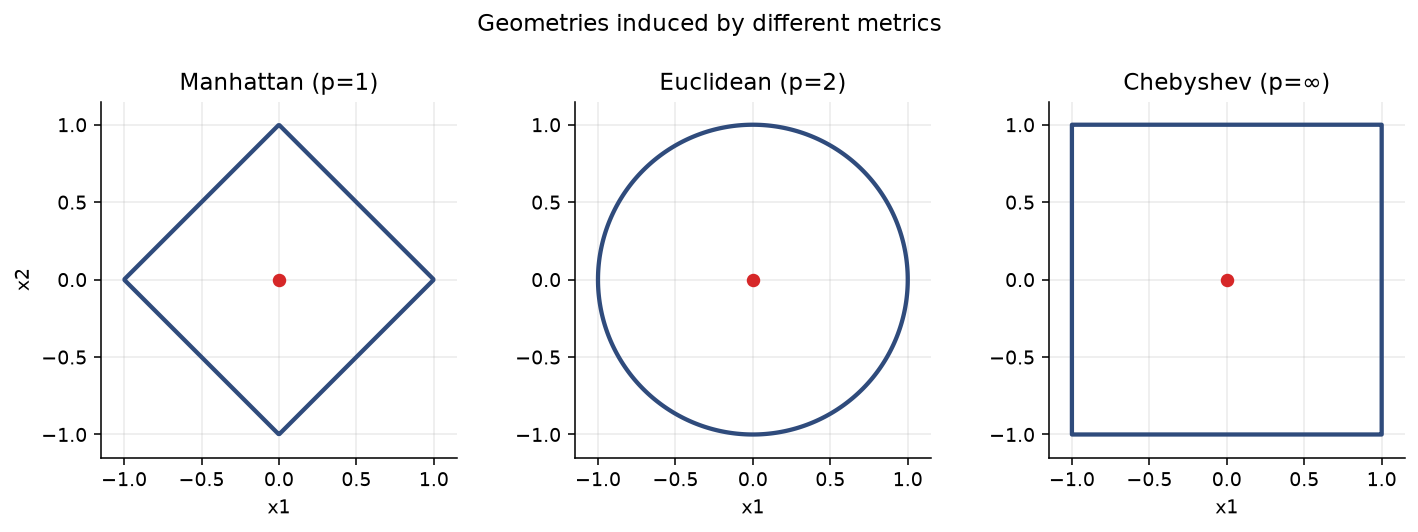

In [2]:
# Create a 2D grid centered at the origin.
# Each grid point represents a possible difference between two vectors.
grid = np.linspace(-1.2, 1.2, 360)
xx, yy = np.meshgrid(grid, grid)

# We calculate three distances from the origin.
# The d=1 level curve shows the unit ball for each metric.
dist_l1 = np.abs(xx) + np.abs(yy)                 # Manhattan
dist_l2 = np.sqrt(xx**2 + yy**2)                  # Euclidean
dist_linf = np.maximum(np.abs(xx), np.abs(yy))    # Chebyshev

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))

for ax, dist, title in zip(
    axes,
    [dist_l1, dist_l2, dist_linf],
    ["Manhattan (p=1)", "Euclidean (p=2)", "Chebyshev (p=∞)"],
):
    # Plot only the curve whose distance from the origin is 1.
    ax.contour(xx, yy, dist, levels=[1.0], colors=["#2f4b7c"], linewidths=2.2)
    ax.scatter([0], [0], color="#d62728", s=35, zorder=3)
    ax.set_aspect("equal")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_title(title)
    ax.set_xlabel("x1")

axes[0].set_ylabel("x2")
fig.suptitle("Geometries induced by different metrics", y=1.03)
fig.tight_layout()

# Figure used in the slides.
fig.savefig(FIG_DIR / "knn_distance_metrics.png", bbox_inches="tight")
plt.show()

## 3. Uniform and distance-weighted voting

The slides distinguish two ideas:

1. **uniform voting:** each neighbor counts as one vote;
2. **distance-weighted voting:** closer neighbors have greater weight.

The cell below uses a small numerical example to make the decision rule clear.

In [3]:
# Instructional example: five nearest neighbors of a new sample.
# Each neighbor has a class and a distance from the new point.
neighbors = pd.DataFrame({
    "neighbor": [1, 2, 3, 4, 5],
    "class_label": ["red", "blue", "red", "red", "blue"],
    "distance": [0.35, 0.42, 0.60, 0.75, 0.95],
})

# Uniform voting:
# Count how often each class appears among the k neighbors.
uniform_votes = neighbors["class_label"].value_counts()

# Distance-weighted voting:
# Use weight = 1 / (distance + epsilon).
# Epsilon prevents division by zero when the distance is exactly zero.
epsilon = 1e-9
neighbors["weight"] = 1.0 / (neighbors["distance"] + epsilon)
weighted_votes = neighbors.groupby("class_label")["weight"].sum().sort_values(ascending=False)

print("Neighbors considered:")
display(neighbors)

print("\nUniform voting:")
display(uniform_votes)

print("\nDistance-weighted voting:")
display(weighted_votes)

Neighbors considered:


,neighbor,class_label,distance,weight
0,1,red,0.35,2.857143
1,2,blue,0.42,2.380952
2,3,red,0.60,1.666667
3,4,red,0.75,1.333333
4,5,blue,0.95,1.052632



Uniform voting:


class_label
red     3
blue    2
Name: count, dtype: int64


Distance-weighted voting:


class_label
red     5.857143
blue    3.433584
Name: weight, dtype: float64

## 4. Synthetic data: electric motor sensors

This section generates the synthetic dataset used in the first slide example.

The instructional interpretation is:

- each row is a measurement window from an electric motor;
- `x1` represents estimated RMS current;
- `x2` represents estimated THD;
- the target represents an operating condition: normal, misalignment, or electrical fault.

In [4]:
# make_classification creates a controlled dataset for demonstration.
# We use two variables because this allows plotting the points and boundaries.
X_raw, y = make_classification(
    n_samples=360,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_classes=3,
    n_clusters_per_class=1,
    class_sep=1.35,
    flip_y=0.04,          # small label noise to make the problem realistic
    random_state=RANDOM_STATE,
)

# Rescale both variables to didactic units with an engineering context.
# The idea is to represent RMS current in amps and THD in percent.
current_rms = 8 + 2.1 * X_raw[:, 0]
thd = 5 + 2.4 * X_raw[:, 1]

# In the slides, the feature matrix is simply called X.
X = np.column_stack([current_rms, thd])

# Readable names for the classes.
class_names = np.array(["Normal", "Misalignment", "Electrical fault"])

# Auxiliary table for visualization only.
df_motor = pd.DataFrame(X, columns=["current_rms_A", "thd_percent"])
df_motor["class_label"] = class_names[y]

df_motor.head()

,current_rms_A,thd_percent,class_label
0,11.454795,1.114749,Normal
1,11.034021,1.200571,Normal
2,9.226310,3.760848,Normal
3,12.330529,14.201700,Misalignment
4,5.735804,-1.358497,Electrical fault


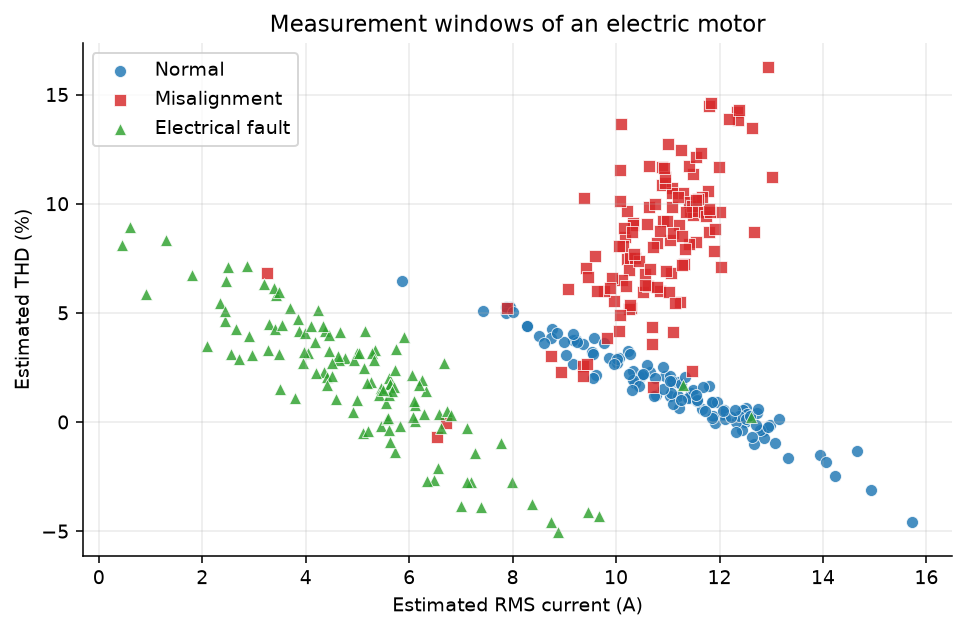

In [5]:
# Scatter figure used in the slides: knn_motor_data.png.
colors = ["#1f77b4", "#d62728", "#2ca02c"]
markers = ["o", "s", "^"]

fig, ax = plt.subplots(figsize=(7.0, 4.6))

for cls, color, marker in zip(range(3), colors, markers):
    mask = y == cls
    ax.scatter(
        X[mask, 0],
        X[mask, 1],
        s=38,
        alpha=0.82,
        color=color,
        marker=marker,
        edgecolor="white",
        linewidth=0.45,
        label=class_names[cls],
    )

ax.set_xlabel("Estimated RMS current (A)")
ax.set_ylabel("Estimated THD (%)")
ax.set_title("Measurement windows of an electric motor")
ax.legend(frameon=True)
fig.tight_layout()

# Figure included in the 'Synthetic data: motor sensors' slide.
fig.savefig(FIG_DIR / "knn_motor_data.png", bbox_inches="tight")
plt.show()

## 5. Training/test split

This cell corresponds to the **Training/test data split** slide.

Using `stratify=y` is important because it preserves similar proportions of the three classes in the training and test sets.

In [6]:
# Split the data before training the model.
# The test set is reserved for evaluating the model on unseen samples.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:  {X_test.shape[0]}")
print("Class distribution in training:")
display(pd.Series(class_names[y_train]).value_counts())
print("Class distribution in test:")
display(pd.Series(class_names[y_test]).value_counts())

Training samples: 252
Test samples:  108
Class distribution in training:


Misalignment        88
Electrical fault    83
Normal              81
Name: count, dtype: int64

Class distribution in test:


Misalignment        37
Electrical fault    36
Normal              35
Name: count, dtype: int64

## 6. Pipeline with scaling and KNN

KNN uses distances, so feature scales matter.

The slides use:

```python
Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7, weights="distance")),
])
```

The `Pipeline` prevents data leakage: `StandardScaler` learns the mean and standard deviation from training data only, then applies the same transformation to the test set.

In [7]:
# Pipeline used in the slide.
# StandardScaler standardizes the variables: mean 0 and standard deviation 1.
# KNeighborsClassifier implements KNN itself.
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
    )),
])

# fit: learns the scaling statistics and stores the training examples.
knn_model.fit(X_train, y_train)

# predict: classifies the test samples.
y_pred = knn_model.predict(X_test)

# Accuracy shown in the slides.
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_accuracy:.3f}")

# Per-class report: precision, recall and F1-score.
print(classification_report(y_test, y_pred, target_names=class_names))

Test accuracy: 0.963
                  precision    recall  f1-score   support

          Normal       0.90      1.00      0.95        35
    Misalignment       1.00      0.89      0.94        37
Electrical fault       1.00      1.00      1.00        36

        accuracy                           0.96       108
       macro avg       0.97      0.96      0.96       108
    weighted avg       0.97      0.96      0.96       108



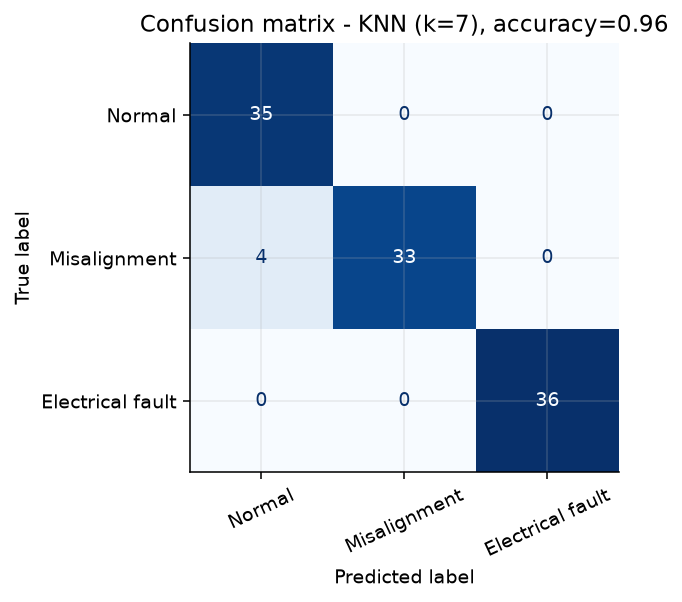

In [8]:
# Confusion matrix used in the slides: knn_confusion_matrix.png.
# Rows: true classes. Columns: predicted classes.
fig, ax = plt.subplots(figsize=(5.3, 4.4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title(f"Confusion matrix - KNN (k=7), accuracy={test_accuracy:.2f}")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(FIG_DIR / "knn_confusion_matrix.png", bbox_inches="tight")
plt.show()

## 7. Effect of k on the decision boundary

The **How does k change the boundary?** slide compares `k=1`, `k=7`, and `k=31`.

Interpretation:

- `k=1`: highly local model, irregular boundary, greater overfitting risk;
- `k=7`: intermediate smoothing;
- `k=31`: smoother boundary, greater underfitting risk.

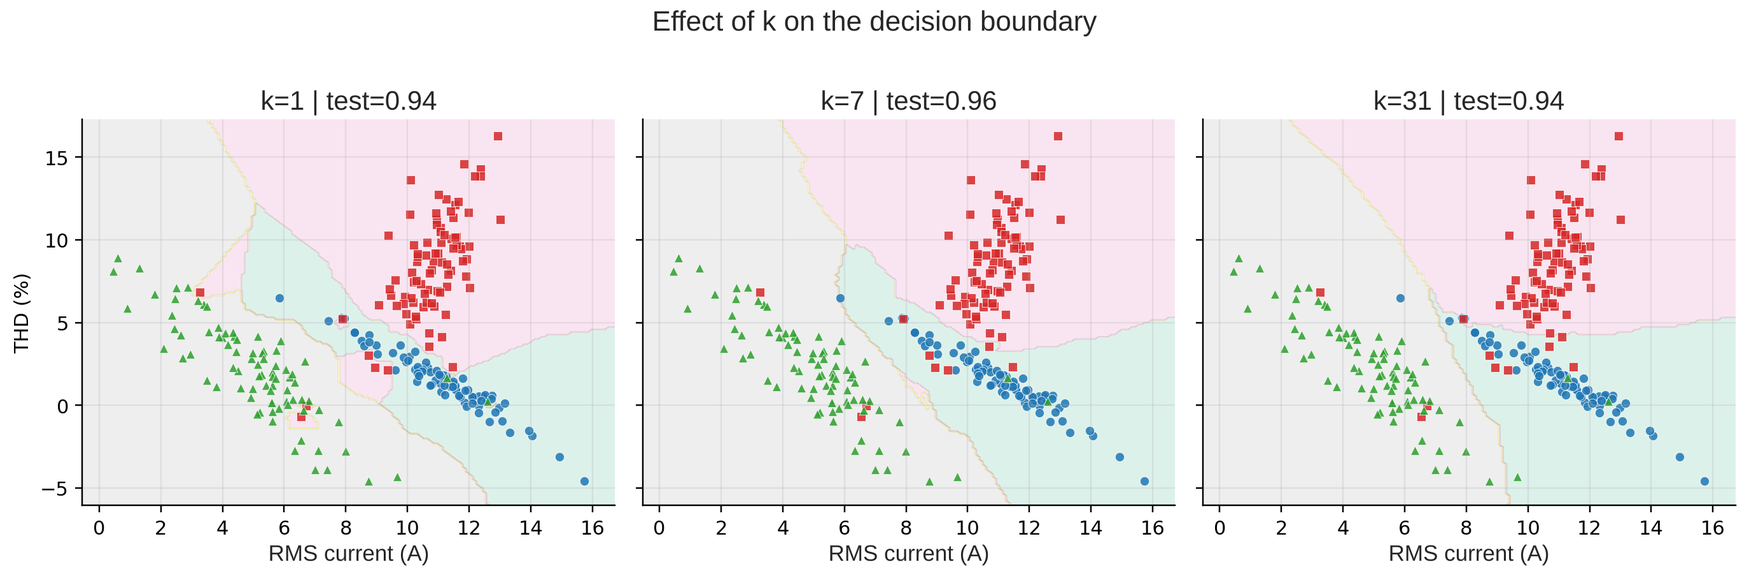

In [9]:
# Create three KNN models with different k values.
# For each value, draw the plane region classified as each class.
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.0), sharex=True, sharey=True)

for ax, k in zip(axes, [1, 7, 31]):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    model.fit(X_train, y_train)

    # DecisionBoundaryDisplay evaluates the model on a grid of points.
    # The result shows the decision boundary induced by KNN.
    DecisionBoundaryDisplay.from_estimator(
        model,
        X,
        response_method="predict",
        grid_resolution=160,
        alpha=0.22,
        cmap=plt.cm.Set2,
        ax=ax,
    )

    # Overlay the training points to ease interpretation.
    for cls, color, marker in zip(range(3), colors, markers):
        mask = y_train == cls
        ax.scatter(
            X_train[mask, 0],
            X_train[mask, 1],
            s=22,
            color=color,
            marker=marker,
            edgecolor="white",
            linewidth=0.3,
            alpha=0.85,
        )

    acc = model.score(X_test, y_test)
    ax.set_title(f"k={k} | test={acc:.2f}")
    ax.set_xlabel("RMS current (A)")

axes[0].set_ylabel("THD (%)")
fig.suptitle("Effect of k on the decision boundary", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "knn_k_boundaries.png", bbox_inches="tight")
plt.show()

## 8. Selecting k with cross-validation

We use five-fold stratified cross-validation to choose `k`.  
The test set is reserved for final evaluation and must not be used to select the hyperparameter.

In [10]:
# Candidate values for k.
# Use only odd values to reduce the chance of voting ties.
k_values = list(range(1, 42, 2))

# StratifiedKFold keeps similar class proportions in each fold.
# Stratified 5-fold cross-validation with shuffling and fixed seed for reproducibility.
# Shuffling randomly mixes the sample order before splitting into folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train_scores = []
cv_means = []
cv_stds = []
test_scores = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])

    # Training accuracy: useful to observe overfitting trends.
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

    # Cross-validation accuracy:
    # the model is refit in each fold, always with the scaler inside the pipeline.
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

# Best k according to mean cross-validation accuracy.
best_idx = int(np.argmax(cv_means))
best_k = k_values[best_idx]
best_cv = cv_means[best_idx]

print(f"Best k by cross-validation: {best_k}")
print(f"Mean validation accuracy: {best_cv:.3f}")

Best k by cross-validation: 5
Mean validation accuracy: 0.956


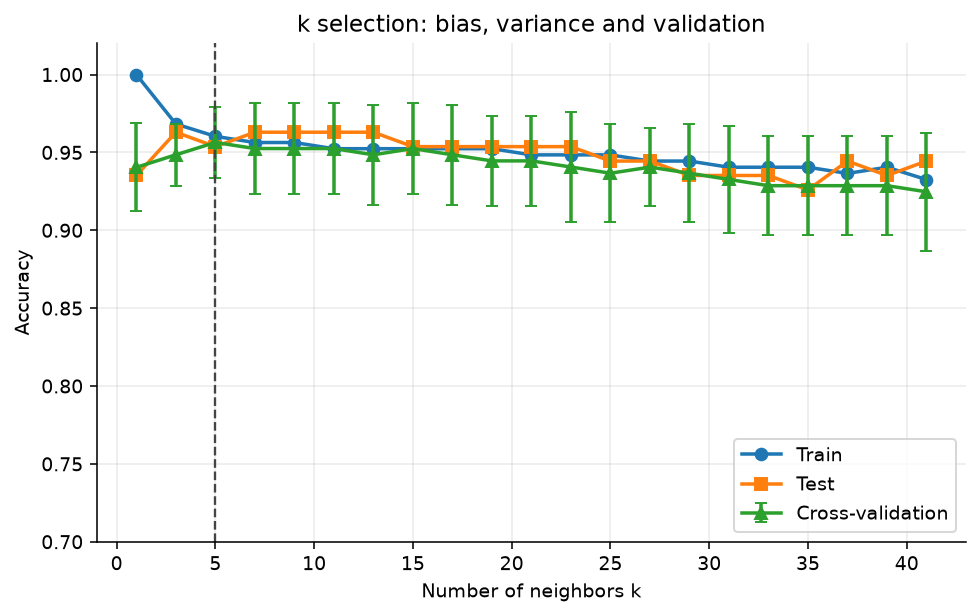

In [11]:
fig, ax = plt.subplots(figsize=(7.1, 4.5))

ax.plot(k_values, train_scores, marker="o", linewidth=1.8, label="Train")
ax.plot(k_values, test_scores, marker="s", linewidth=1.8, label="Test")
ax.errorbar(
    k_values,
    cv_means,
    yerr=cv_stds,
    marker="^",
    linewidth=1.8,
    capsize=3,
    label="Cross-validation",
)

ax.axvline(best_k, color="#444444", linestyle="--", linewidth=1.2)
ax.set_xlabel("Number of neighbors k")
ax.set_ylabel("Accuracy")
ax.set_title("k selection: bias, variance and validation")
ax.set_ylim(0.70, 1.02)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "knn_k_selection.png", bbox_inches="tight")
plt.show()

## 9. Feature scaling

Here we run a simple numerical test: multiply THD by 20 and compare KNN with and without scaling.

This section does not generate a figure for the final slides; it supports the **KNN depends on scale** slide.

In [12]:
# Copy the data and artificially change the scale of the second variable.
# This simulates a common engineering situation: features measured in very different units.
X_bad_scale = X.copy()
X_bad_scale[:, 1] *= 20.0

X_train_bad, X_test_bad, y_train_bad, y_test_bad = train_test_split(
    X_bad_scale,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Model without normalization: distances are computed directly in the original scales.
plain_knn = KNeighborsClassifier(n_neighbors=7)
plain_knn.fit(X_train_bad, y_train_bad)
acc_plain = plain_knn.score(X_test_bad, y_test_bad)

# Model with normalization: each feature has mean 0 and standard deviation 1.
scaled_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=7)),
])
scaled_knn.fit(X_train_bad, y_train_bad)
acc_scaled = scaled_knn.score(X_test_bad, y_test_bad)

print(f"Accuracy without normalization: {acc_plain:.3f}")
print(f"Accuracy with normalization: {acc_scaled:.3f}")

Accuracy without normalization: 0.880
Accuracy with normalization: 0.963


## 10. Case study: smart grid stability

This section corresponds to the case study in the slides.

Dataset used:

> Arzamasov, V. (2018). *Electrical Grid Stability Simulated Data*. UCI Machine Learning Repository.  
> DOI: https://doi.org/10.24432/C5PG66

The `stabf` target indicates whether the grid is `stable` or `unstable`.

In [13]:
# Read the .zip file downloaded from UCI directly.
# pandas can open the inner CSV without manual extraction.
uci_path = Path("data") / "electrical_grid_stability_uci.zip"
grid_df = pd.read_csv(uci_path)

print(f"UCI dataset size: {grid_df.shape[0]} rows x {grid_df.shape[1]} columns")
print("\nClass distribution:")
display(grid_df["stabf"].value_counts())

grid_df.head()

UCI dataset size: 10000 rows x 14 columns

Class distribution:


stabf
unstable    6380
stable      3620
Name: count, dtype: int64

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


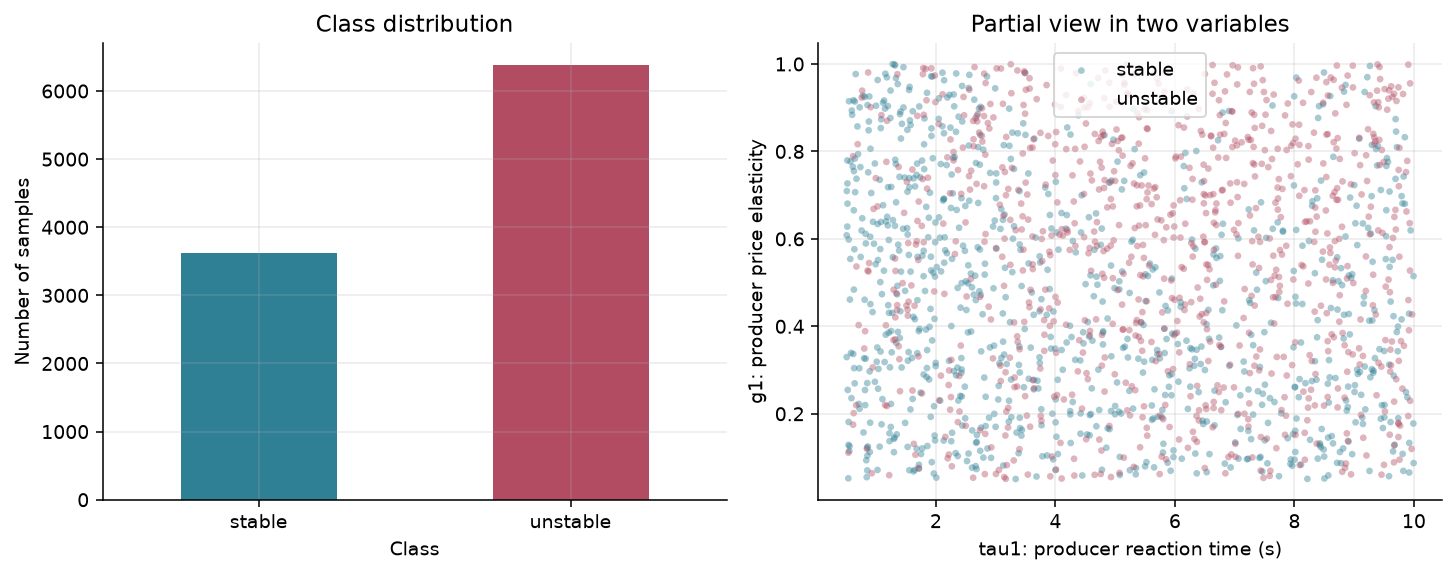

In [14]:
# Figure used in the slides
# It shows the class distribution and a 2D projection with only tau1 and g1.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

grid_df["stabf"].value_counts().reindex(["stable", "unstable"]).plot(
    kind="bar",
    ax=axes[0],
    color=["#2f7f95", "#b24c63"],
    rot=0,
)
axes[0].set_title("Class distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of samples")

# Sample points to avoid overloading the visualization.
# The model uses 12 variables; this projection is only for visual inspection.
for label, color in zip(["stable", "unstable"], ["#2f7f95", "#b24c63"]):
    sample = grid_df[grid_df["stabf"] == label].sample(
        900,
        random_state=RANDOM_STATE,
        replace=False,
    )
    axes[1].scatter(
        sample["tau1"],
        sample["g1"],
        s=12,
        alpha=0.42,
        color=color,
        label=label,
        edgecolor="none",
    )

axes[1].set_xlabel("tau1: producer reaction time (s)")
axes[1].set_ylabel("g1: producer price elasticity")
axes[1].set_title("Partial view in two variables")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "uci_grid_distribution_scatter.png", bbox_inches="tight")
plt.show()

## 11. KNN on the UCI dataset

We use the 12 predictor variables `tau`, `p`, and `g`.  
The `stab` column is removed because it is a continuous measure directly associated with stability; the slides classify `stabf`.

Target encoding:

- `0`: stable;
- `1`: unstable.

In [15]:
# Input variables used by the model.
feature_cols = [
    "tau1", "tau2", "tau3", "tau4",
    "p1", "p2", "p3", "p4",
    "g1", "g2", "g3", "g4",
]

X_grid = grid_df[feature_cols].to_numpy()
y_grid = (grid_df["stabf"] == "unstable").astype(int).to_numpy()
grid_class_names = np.array(["stable", "unstable"])

# Train/test split preserving class proportions.
Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    X_grid,
    y_grid,
    test_size=0.25,
    stratify=y_grid,
    random_state=RANDOM_STATE,
)

# Model used in the slides:
# standardization + KNN with k=13 and distance weights.
grid_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=13, weights="distance")),
])

grid_knn.fit(Xg_train, yg_train)
yg_pred = grid_knn.predict(Xg_test)
grid_acc = accuracy_score(yg_test, yg_pred)

print(f"UCI smart grid accuracy: {grid_acc:.3f}")
print(classification_report(yg_test, yg_pred, target_names=grid_class_names))

UCI smart grid accuracy: 0.867
              precision    recall  f1-score   support

      stable       0.93      0.68      0.79       905
    unstable       0.84      0.97      0.90      1595

    accuracy                           0.87      2500
   macro avg       0.89      0.83      0.85      2500
weighted avg       0.88      0.87      0.86      2500



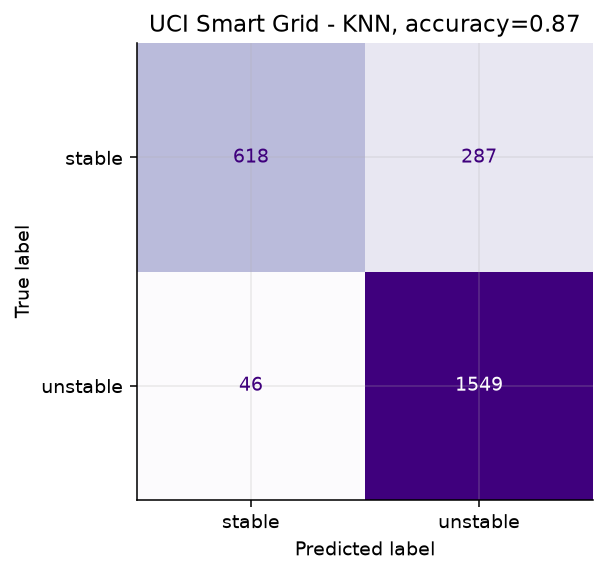

Unstable grids in test: 1595
Unstable classified as stable: 46


In [16]:
# Confusion matrix used in the slides: uci_grid_confusion_matrix.png.
fig, ax = plt.subplots(figsize=(5.0, 4.2))

ConfusionMatrixDisplay.from_predictions(
    yg_test,
    yg_pred,
    display_labels=grid_class_names,
    cmap="Purples",
    colorbar=False,
    ax=ax,
)

ax.set_title(f"UCI Smart Grid - KNN, accuracy={grid_acc:.2f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "uci_grid_confusion_matrix.png", bbox_inches="tight")
plt.show()

# Critical error discussed in the slides:
# truly unstable grid (1) classified as stable (0).
critical_errors = int(((yg_test == 1) & (yg_pred == 0)).sum())
unstable_total = int((yg_test == 1).sum())

print(f"Unstable grids in test: {unstable_total}")
print(f"Unstable classified as stable: {critical_errors}")

## 12. Choosing k on the UCI dataset

In the case study, the slides test `k = 1, 5, 9, ..., 41`.  
Again, we use five-fold stratified cross-validation.

In [17]:
grid_k_values = list(range(1, 42, 4))
grid_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_cv_means = []
grid_test_scores = []

for k in grid_k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights="distance")),
    ])

    # Cross-validation on the training set only.
    scores = cross_val_score(model, Xg_train, yg_train, cv=grid_cv, scoring="accuracy")
    grid_cv_means.append(scores.mean())

    # The test curve is computed for didactic purposes.
    # In practice, the test set should be used only once on the chosen model.
    model.fit(Xg_train, yg_train)
    grid_test_scores.append(model.score(Xg_test, yg_test))

grid_best_idx = int(np.argmax(grid_cv_means))
grid_best_k = grid_k_values[grid_best_idx]
grid_best_cv = grid_cv_means[grid_best_idx]

print(f"Best k on UCI dataset: {grid_best_k}")
print(f"Mean validation accuracy: {grid_best_cv:.3f}")

Best k on UCI dataset: 17
Mean validation accuracy: 0.857


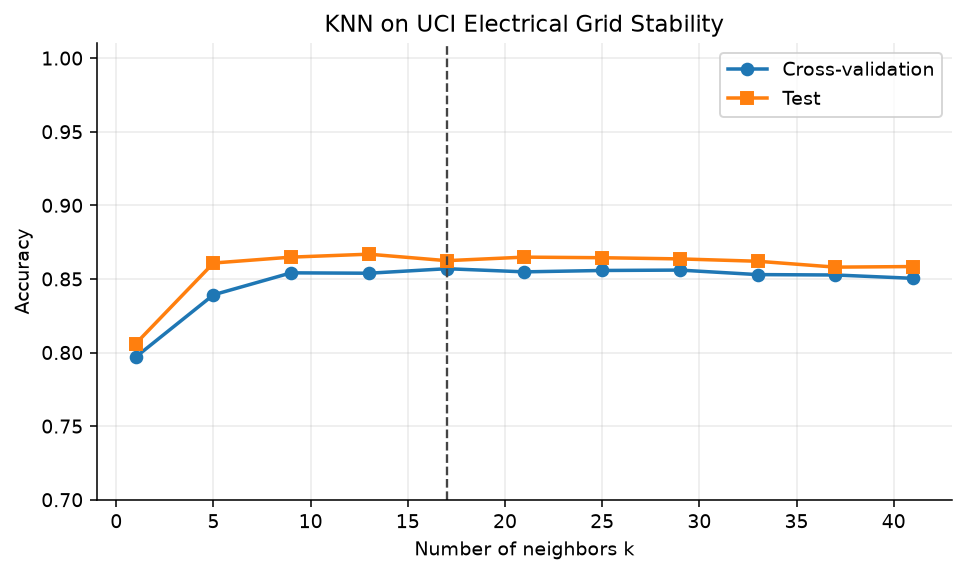

In [18]:
# Figure used in the slides: uci_grid_k_selection.png.
fig, ax = plt.subplots(figsize=(7.0, 4.2))

ax.plot(grid_k_values, grid_cv_means, marker="o", linewidth=1.8, label="Cross-validation")
ax.plot(grid_k_values, grid_test_scores, marker="s", linewidth=1.8, label="Test")
ax.axvline(grid_best_k, color="#444444", linestyle="--", linewidth=1.2)

ax.set_xlabel("Number of neighbors k")
ax.set_ylabel("Accuracy")
ax.set_title("KNN on UCI Electrical Grid Stability")
ax.set_ylim(0.70, 1.01)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "uci_grid_k_selection.png", bbox_inches="tight")
plt.show()

## 13. Guided practice

Suggested experiments to accompany the final slide exercises:

1. Replace `weights="distance"` with `weights="uniform"` in the motor example and compare the confusion matrix.
2. Try `metric="manhattan"` in `KNeighborsClassifier`.
3. Add a third synthetic variable, such as winding temperature, and repeat cross-validation.
4. In the UCI dataset, remove `p1` and compare accuracy.
5. In the UCI dataset, explicitly calculate the rate of unstable grids classified as stable.